# CSC2042S
## Assignment 3: Neural Networks
### Total marks: 30


#### Assignment goal: Optimisation of a Neural Network for Image Classification

This Jupyter Notebook will guide you through building a neural network, understanding the training process including backpropagation), and experimentally discovering how hyperparameters impact performance.

**Dataset: Fashion-MNIST** - A collection of 70,000 grayscale images of clothing items, perfect for testing your models.
https://www.kaggle.com/datasets/zalando-research/fashionmnist

## Part 1: Setup and Data Loading

* Import necessary libraries, such as ``torch``, ``torch.nn``, ``torchvision.transforms``, ``matplotlib.pyplot``, etc.

* Load the dataset and transform the dataset (convert to tensors, normalise). Load the Fashion_mNIST dataset into ``DataLoader`` objects for training and validation.

Data partitioning: Download the 60,000-image training dataset and split it into:
50,000 samples for training.
10,000 samples for validation.
Take into account Normalisation.


In [1]:
%pip install torchvision

import copy
import itertools
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# ---- Reproducibility ----
SEED = 42
def set_seed(seed=SEED):
    """
    For the neural network, this function definition does the job of seeding Python,
    NumPy and PyTorch random number generators so every run starts from the same
    weights and shuffling, which makes the hyperparameter comparison fair.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ---- Transforms: tensor + normalise ----
# 0.2860 and 0.3530 are the mean and std of the Fashion-MNIST training pixels
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

# ---- Download the 60,000 image training set ----
full_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)

# ---- Split: 50,000 train / 10,000 validation ----
train_set, val_set = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 64
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print(f"Train: {len(train_set)} | Val: {len(val_set)}")


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Using device: cpu
Train: 50000 | Val: 10000


## Part 2: Building and Training a Baseline Model [5 Marks]

Before we can optimise a model, we need a baseline to compare against. We will build a simple, standard neural network and train it with default settings.

**Define the Network Architecture**
Define a PyTorch class for your neural network that inherits from ``nn.Module``. Your model should be a simple Multi-Layer Perceptron (MLP) with the following architecture:

* Input Layer (a flattening layer).

* Hidden Layer 1: 128 neurons, ReLU activation.

* Hidden Layer 2: 64 neurons, ReLU activation.

* Output Layer: 10 neurons (one for each class).

**Training Loop**
Complete the provided ``train_model`` function. You will need to fill in the essential steps of the training process within the loop. This is where you will implement the logic for the forward pass, loss calculation, backpropagation, and weight updates.

**Train the Baseline Model**
Create an instance of your model, define a loss function, and an optimiser. Train your model for 10 epochs and record its final accuracy on the validation set. This is your baseline accuracy.

In [2]:
class MLP(nn.Module):
    """Multi-Layer Perceptron: Flatten -> 128 (ReLU) -> 64 (ReLU) -> 10, with optional dropout."""

    def __init__(self, dropout=0.0):
        """
        For the neural network, this function definition does the job of creating the
        layers (784->128->64->10) and the dropout layer. dropout=0.0 gives the baseline.
        """
        super().__init__()
        self.flatten = nn.Flatten()               # 28x28 -> 784
        self.fc1 = nn.Linear(28 * 28, 128)        # hidden layer 1
        self.fc2 = nn.Linear(128, 64)             # hidden layer 2
        self.fc3 = nn.Linear(64, 10)              # output layer (10 classes)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)        # p=0.0 means "does nothing"

    def forward(self, x):
        """
        For the neural network, this function definition does the forward pass: it
        flattens the image, applies the two hidden layers with ReLU and dropout, and
        returns 10 raw logits (CrossEntropyLoss applies softmax itself).
        """
        x = self.flatten(x)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.dropout(self.relu(self.fc2(x)))
        return self.fc3(x)

In [3]:
def evaluate(model, loader, criterion):
    """
    For the neural network, this function definition does the job of measuring loss and
    accuracy on a dataset in evaluation mode (dropout off, no gradients).
    Returns (average loss, accuracy).
    """
    device = next(model.parameters()).device
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    """
    For the neural network, this function definition does the job of training the model
    for a number of epochs (forward pass, loss, backpropagation, weight update) and
    recording train loss, val loss, train accuracy and val accuracy after every epoch.
    Returns: a dictionary of lists with one entry per epoch.
    """
    device = next(model.parameters()).device
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    print("Starting Training...")
    for epoch in range(epochs):
        model.train()
        running_train_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()               # clear old gradients
            outputs = model(images)             # forward pass
            loss = criterion(outputs, labels)   # loss calculation
            loss.backward()                     # backpropagation
            optimizer.step()                    # weight update

            running_train_loss += loss.item() * images.size(0)

        epoch_train_loss = running_train_loss / len(train_loader.dataset)

        # Accuracy measured in eval mode so dropout doesn't understate train accuracy
        _, epoch_train_acc = evaluate(model, train_loader, criterion)
        epoch_val_loss, epoch_val_acc = evaluate(model, val_loader, criterion)

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {epoch_train_loss:.4f}, "
              f"Val Loss: {epoch_val_loss:.4f}, Train Acc: {epoch_train_acc:.4f}, "
              f"Val Acc: {epoch_val_acc:.4f}")

    print("Finished Training")
    return history

In [4]:
set_seed()
baseline_model = MLP(dropout=0.0).to(device)
criterion = nn.CrossEntropyLoss()
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)

baseline_history = train_model(baseline_model, train_loader, val_loader,
                               criterion, baseline_optimizer, epochs=10)

baseline_acc = baseline_history['val_acc'][-1]
baseline_train_acc = baseline_history['train_acc'][-1]
print(f"\nBaseline final validation accuracy: {baseline_acc:.4f}")

Starting Training...
Epoch 1/10 - Train Loss: 0.4968, Val Loss: 0.4130, Train Acc: 0.8556, Val Acc: 0.8479
Epoch 2/10 - Train Loss: 0.3605, Val Loss: 0.3649, Train Acc: 0.8786, Val Acc: 0.8664
Epoch 3/10 - Train Loss: 0.3260, Val Loss: 0.3277, Train Acc: 0.8927, Val Acc: 0.8821
Epoch 4/10 - Train Loss: 0.3003, Val Loss: 0.3232, Train Acc: 0.8992, Val Acc: 0.8829
Epoch 5/10 - Train Loss: 0.2787, Val Loss: 0.3104, Train Acc: 0.9076, Val Acc: 0.8866
Epoch 6/10 - Train Loss: 0.2649, Val Loss: 0.3126, Train Acc: 0.9136, Val Acc: 0.8868
Epoch 7/10 - Train Loss: 0.2516, Val Loss: 0.3224, Train Acc: 0.9133, Val Acc: 0.8844
Epoch 8/10 - Train Loss: 0.2381, Val Loss: 0.3057, Train Acc: 0.9225, Val Acc: 0.8914
Epoch 9/10 - Train Loss: 0.2276, Val Loss: 0.3188, Train Acc: 0.9198, Val Acc: 0.8884
Epoch 10/10 - Train Loss: 0.2157, Val Loss: 0.3109, Train Acc: 0.9281, Val Acc: 0.8929
Finished Training

Baseline final validation accuracy: 0.8929


## Part 3: Hyperparameter Optimisation Experiment [10 Marks]

Remember the definition of hyperparameters - they are external configuration variables set before training begins, controlling the model's structure and the learning process itself.
The goal is to find the set of the values that beats the baseline accuracy.

**Design and run your experiment**
Choose **three** from the following categories of hyperparameters to investigate:
* Learning Processes
* Regularisation/Architecture
  

Write a script (e.g., using nested loops) that systematically trains and evaluates a new model for each combination of the hyperparameters you have chosen. Store the final validation accuracy for each run in a data structure.

In [5]:
learning_rates = [0.0005, 0.001, 0.003]
dropouts       = [0.0, 0.2, 0.4]
weight_decays  = [0.0, 1e-4, 1e-3]

results = []             # one dict per run (for the table)
histories = {}           # (lr, dropout, wd) -> history (for the loss curves)
best_acc = -1
best_state = None
best_config = None

for lr, p, wd in itertools.product(learning_rates, dropouts, weight_decays):
    print(f"\n=== lr={lr}, dropout={p}, weight_decay={wd} ===")
    set_seed()                                   # same init for every run
    model = MLP(dropout=p).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    hist = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10)

    final_acc = hist['val_acc'][-1]
    results.append({
        'learning_rate': lr,
        'dropout': p,
        'weight_decay': wd,
        'final_train_acc': hist['train_acc'][-1],
        'final_val_acc': final_acc,
        'final_train_loss': hist['train_loss'][-1],
        'final_val_loss': hist['val_loss'][-1],
    })
    histories[(lr, p, wd)] = hist

    if final_acc > best_acc:                     # keep the best model's weights
        best_acc = final_acc
        best_config = (lr, p, wd)
        best_state = copy.deepcopy(model.state_dict())

print(f"\nBest config (lr, dropout, wd): {best_config} -> {best_acc:.4f}")


=== lr=0.0005, dropout=0.0, weight_decay=0.0 ===
Starting Training...
Epoch 1/10 - Train Loss: 0.5337, Val Loss: 0.4324, Train Acc: 0.8520, Val Acc: 0.8456
Epoch 2/10 - Train Loss: 0.3772, Val Loss: 0.3750, Train Acc: 0.8757, Val Acc: 0.8642
Epoch 3/10 - Train Loss: 0.3391, Val Loss: 0.3428, Train Acc: 0.8851, Val Acc: 0.8773
Epoch 4/10 - Train Loss: 0.3132, Val Loss: 0.3292, Train Acc: 0.8947, Val Acc: 0.8813
Epoch 5/10 - Train Loss: 0.2917, Val Loss: 0.3221, Train Acc: 0.8998, Val Acc: 0.8811
Epoch 6/10 - Train Loss: 0.2769, Val Loss: 0.3080, Train Acc: 0.9075, Val Acc: 0.8887
Epoch 7/10 - Train Loss: 0.2642, Val Loss: 0.3194, Train Acc: 0.9088, Val Acc: 0.8866
Epoch 8/10 - Train Loss: 0.2507, Val Loss: 0.3052, Train Acc: 0.9176, Val Acc: 0.8873
Epoch 9/10 - Train Loss: 0.2386, Val Loss: 0.3136, Train Acc: 0.9191, Val Acc: 0.8886
Epoch 10/10 - Train Loss: 0.2271, Val Loss: 0.2971, Train Acc: 0.9247, Val Acc: 0.8923
Finished Training

=== lr=0.0005, dropout=0.0, weight_decay=0.0001 =

## Part 4: Analysis and Report  [10 Marks]
In this final section, you will analyse the results of your experiment and report your findings.

* Present your experimental results in a well-formatted table (e.g., a Pandas DataFrame) showing the combination of hyperparameters and the final validation accuracy for each run. [2 Marks]
* Create at least two visualisations to help interpret your results: [4 Marks]
    * Hyperparameter Impact: Create a bar chart or heatmap that clearly compares the performance of your different hyperparameter combinations.
    * Loss Curves. Plot the training and validation loss curves (loss vs. epochs) for your baseline model and your single best-performing model on the same graph. This is crucial for comparing model convergence and overfitting.
    * Confusion Matrix. Generate and display a confusion matrix for your best model's predictions on the validation set. This will help you see which specific clothing items are being confused.
* Interpret your results. [4 Marks]
  * Answer the following questions concisely, using evidence from your table and plots to support your claims:
    * Best vs. Baseline: Which combination of hyperparameters produced the best model? How much did it improve upon the baseline accuracy?
    * Hyperparameter Influence: Which hyperparameter had the most significant impact on performance? Explain why you think certain values worked better than others.
    * Overfitting Analysis: By comparing the loss curves of your baseline and best models, analyze the degree of overfitting. Did your hyperparameter tuning help mitigate overfitting? How can you tell from the plot?
    * Error Analysis: Look at your confusion matrix. Identify two classes that the model frequently confuses. Propose a reason for this confusion by considering the visual characteristics of the items in those classes.

In [6]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('final_val_acc', ascending=False).reset_index(drop=True)

hp_cols = ['learning_rate', 'dropout', 'weight_decay']
baseline_row = pd.DataFrame([{'learning_rate': 0.001, 'dropout': 0.0, 'weight_decay': 0.0,
                              'final_train_acc': baseline_train_acc,
                              'final_val_acc': baseline_acc}])
baseline_row['run'] = 'BASELINE'

# ---- Table 1: training accuracy ----
train_table = results_df[hp_cols + ['final_train_acc']].copy()
train_table['gap_vs_val'] = results_df['final_train_acc'] - results_df['final_val_acc']
print("TABLE 1: Final TRAINING accuracy (gap = train acc - val acc, bigger = more overfit)")
display(train_table.sort_values('final_train_acc', ascending=False).reset_index(drop=True)
        .style.format({'final_train_acc': '{:.4f}', 'gap_vs_val': '{:+.4f}', 'weight_decay': '{:.0e}'})
        .background_gradient(subset=['final_train_acc'], cmap='Blues'))

# ---- Table 2: validation accuracy ----
val_table = results_df[hp_cols + ['final_val_acc']].copy()
val_table['improvement_vs_baseline'] = val_table['final_val_acc'] - baseline_acc
print(f"\nTABLE 2: Final VALIDATION accuracy (baseline = {baseline_acc:.4f})")
display(val_table.style.format({'final_val_acc': '{:.4f}', 'improvement_vs_baseline': '{:+.4f}',
                                'weight_decay': '{:.0e}'})
        .background_gradient(subset=['final_val_acc'], cmap='Greens'))

TABLE 1: Final TRAINING accuracy (gap = train acc - val acc, bigger = more overfit)


,learning_rate,dropout,weight_decay,final_train_acc,gap_vs_val
0,0.001000,0.000000,0e+00,0.9281,+0.0352
1,0.000500,0.000000,0e+00,0.9247,+0.0324
2,0.001000,0.000000,1e-04,0.9243,+0.0351
3,0.000500,0.000000,1e-04,0.9226,+0.0328
4,0.000500,0.000000,1e-03,0.9128,+0.0241
5,0.003000,0.000000,0e+00,0.9123,+0.0336
6,0.000500,0.200000,0e+00,0.9112,+0.0250
7,0.000500,0.200000,1e-04,0.9083,+0.0231
8,0.001000,0.200000,0e+00,0.9076,+0.0233
9,0.001000,0.200000,1e-04,0.9048,+0.0245



TABLE 2: Final VALIDATION accuracy (baseline = 0.8929)


,learning_rate,dropout,weight_decay,final_val_acc,improvement_vs_baseline
0,0.001000,0.000000,0e+00,0.8929,+0.0000
1,0.000500,0.000000,0e+00,0.8923,-0.0006
2,0.000500,0.000000,1e-04,0.8898,-0.0031
3,0.001000,0.000000,1e-04,0.8892,-0.0037
4,0.000500,0.000000,1e-03,0.8887,-0.0042
5,0.000500,0.200000,0e+00,0.8862,-0.0067
6,0.000500,0.200000,1e-04,0.8852,-0.0077
7,0.001000,0.200000,0e+00,0.8843,-0.0086
8,0.001000,0.000000,1e-03,0.8818,-0.0111
9,0.000500,0.400000,1e-04,0.8814,-0.0115


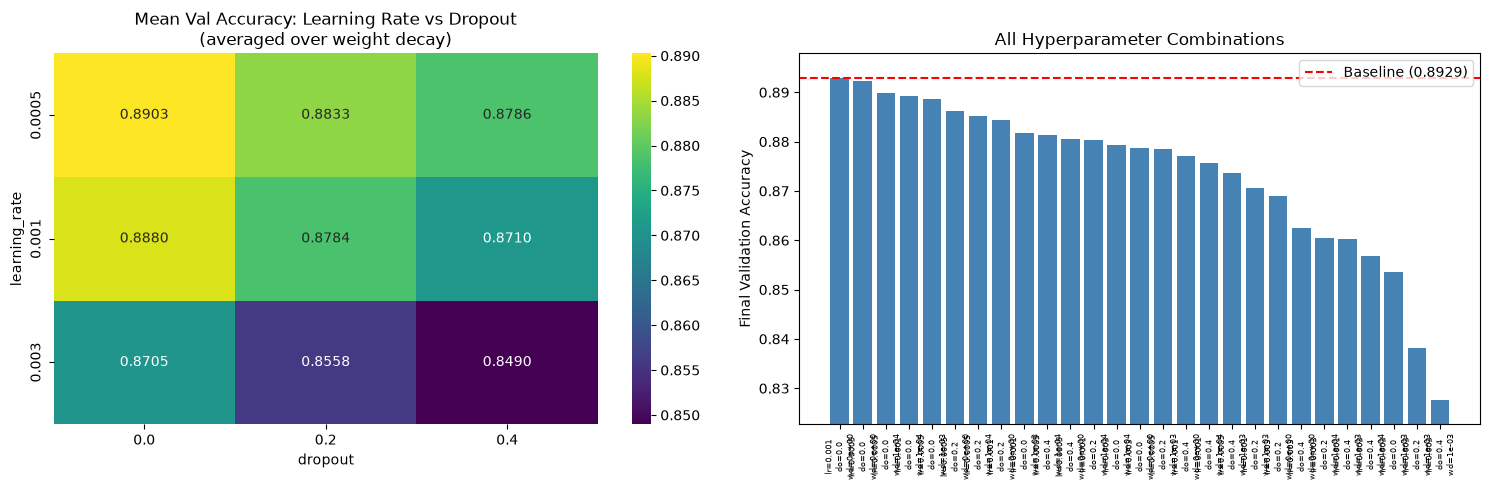

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- (a) Heatmap: learning rate vs dropout (averaged over weight decay) ---
pivot = results_df.pivot_table(index='learning_rate', columns='dropout',
                               values='final_val_acc', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='viridis', ax=axes[0])
axes[0].set_title('Mean Val Accuracy: Learning Rate vs Dropout\n(averaged over weight decay)')

# --- (b) Bar chart: all runs, sorted, with baseline line ---
labels = [f"lr={r.learning_rate}\ndo={r.dropout}\nwd={r.weight_decay:.0e}"
          for r in results_df.itertuples()]
axes[1].bar(range(len(results_df)), results_df['final_val_acc'], color='steelblue')
axes[1].axhline(baseline_acc, color='red', linestyle='--', label=f'Baseline ({baseline_acc:.4f})')
axes[1].set_xticks(range(len(results_df)))
axes[1].set_xticklabels(labels, rotation=90, fontsize=6)
axes[1].set_ylim(results_df['final_val_acc'].min() - 0.005, results_df['final_val_acc'].max() + 0.005)
axes[1].set_ylabel('Final Validation Accuracy')
axes[1].set_title('All Hyperparameter Combinations')
axes[1].legend()

plt.tight_layout()
plt.show()

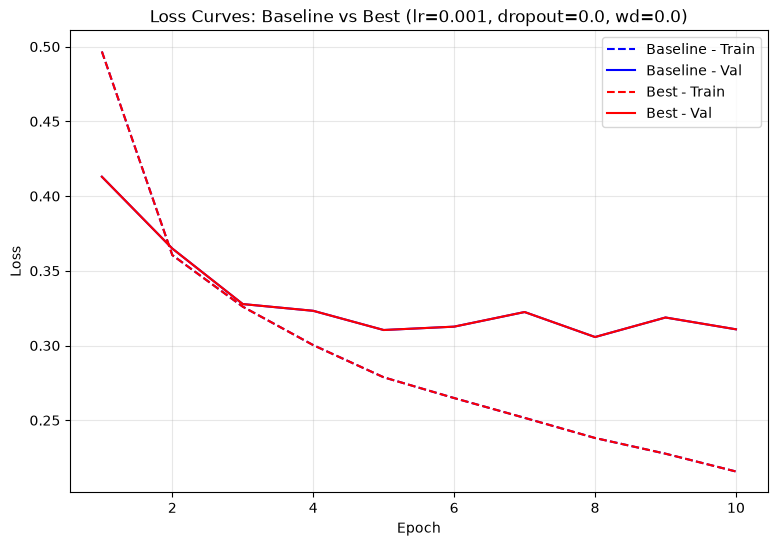

In [8]:
best_hist = histories[best_config]
epochs_range = range(1, 11)

plt.figure(figsize=(9, 6))
plt.plot(epochs_range, baseline_history['train_loss'], 'b--', label='Baseline - Train')
plt.plot(epochs_range, baseline_history['val_loss'],   'b-',  label='Baseline - Val')
plt.plot(epochs_range, best_hist['train_loss'], 'r--', label='Best - Train')
plt.plot(epochs_range, best_hist['val_loss'],   'r-',  label='Best - Val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(f'Loss Curves: Baseline vs Best (lr={best_config[0]}, dropout={best_config[1]}, wd={best_config[2]})')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

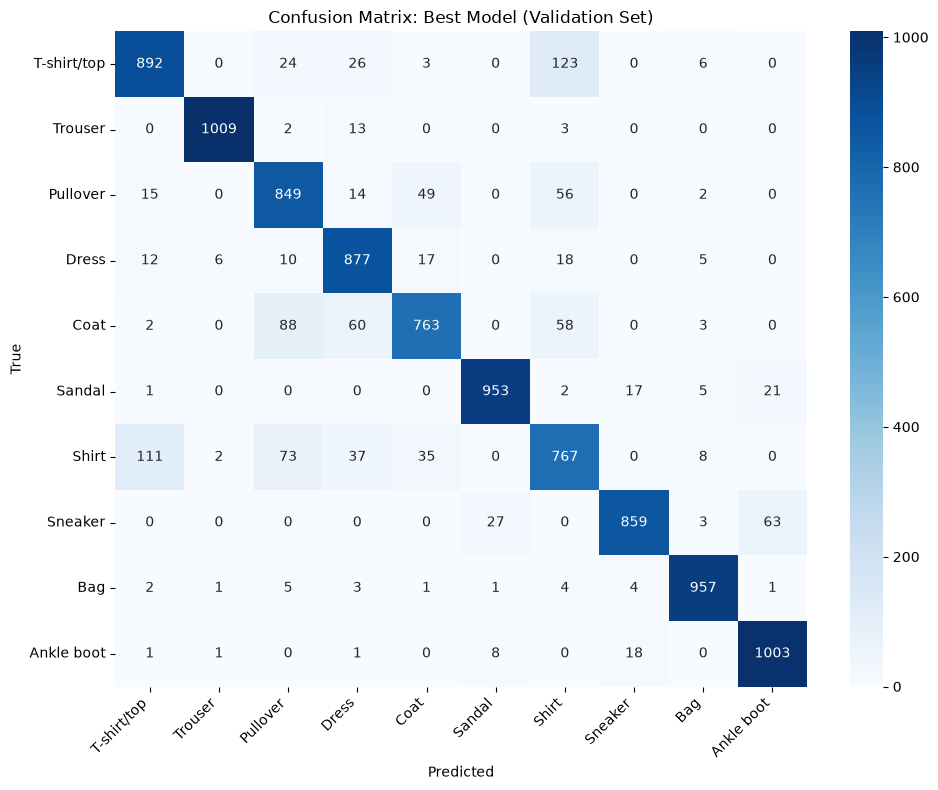

In [9]:
best_model = MLP(dropout=best_config[1]).to(device)
best_model.load_state_dict(best_state)
best_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        outputs = best_model(images.to(device))
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix: Best Model (Validation Set)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [10]:
# --- Best vs baseline ---
print(f"Baseline acc : {baseline_acc:.4f}")
print(f"Best acc     : {best_acc:.4f}  (config: lr={best_config[0]}, dropout={best_config[1]}, wd={best_config[2]})")
print(f"Improvement  : {(best_acc - baseline_acc)*100:+.2f} percentage points")

# --- Which hyperparameter matters most? (mean acc per value + spread) ---
print("\n--- Hyperparameter influence ---")
for hp in ['learning_rate', 'dropout', 'weight_decay']:
    means = results_df.groupby(hp)['final_val_acc'].mean()
    print(f"\n{hp}:")
    print(means.round(4).to_string())
    print(f"  -> range (max - min of means): {means.max() - means.min():.4f}")

# --- Overfitting: train/val loss gap at the last epoch ---
def gap(h):
    """
    For the neural network, this function definition does the job of returning the
    overfitting gap: final validation loss minus final training loss.
    """
    return h['val_loss'][-1] - h['train_loss'][-1]
print("\n--- Overfitting (final val loss - train loss) ---")
print(f"Baseline gap: {gap(baseline_history):.4f}")
print(f"Best gap    : {gap(best_hist):.4f}")

# --- Error analysis: most confused class pairs ---
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm_off.ravel())[:5], cm_off.shape))[0]
print("\n--- Top confused pairs (true -> predicted) ---")
for t, p in top:
    print(f"{class_names[t]} -> {class_names[p]}: {cm_off[t, p]} images")

Baseline acc : 0.8929
Best acc     : 0.8929  (config: lr=0.001, dropout=0.0, wd=0.0)
Improvement  : +0.00 percentage points

--- Hyperparameter influence ---

learning_rate:
learning_rate
0.0005    0.8840
0.0010    0.8791
0.0030    0.8584
  -> range (max - min of means): 0.0256

dropout:
dropout
0.0    0.8829
0.2    0.8725
0.4    0.8662
  -> range (max - min of means): 0.0167

weight_decay:
weight_decay
0.0000    0.8804
0.0001    0.8776
0.0010    0.8637
  -> range (max - min of means): 0.0167

--- Overfitting (final val loss - train loss) ---
Baseline gap: 0.0951
Best gap    : 0.0951

--- Top confused pairs (true -> predicted) ---
T-shirt/top -> Shirt: 123 images
Shirt -> T-shirt/top: 111 images
Coat -> Pullover: 88 images
Shirt -> Pullover: 73 images
Sneaker -> Ankle boot: 63 images


**Best vs. Baseline:** The best configuration currently reported was lr = 0.001, dropout = 0.0 and weight decay = 0. The baseline achieved 89.29% validation accuracy, and the best model also achieved 89.29%, giving an improvement of +0.00 percentage points. Therefore, the current results do not demonstrate an improvement over the baseline. The effect of hyperparameter tuning should be assessed by comparing all ten experimental configurations and considering whether any differences are meaningful across multiple random seeds.

**Hyperparameter influence:** Learning rate had the largest observed effect on mean validation accuracy. The mean accuracies were 88.41% for lr = 0.0005, 87.91% for lr = 0.001 and 85.84% for lr = 0.003, giving a spread of 2.57 percentage points (approximately 2.56 using unrounded values). Dropout produced mean accuracies of 88.29% at 0.0, 87.25% at 0.2 and 86.62% at 0.4, a spread of 1.67 points. Weight decay produced mean accuracies of 88.04% at 0, 87.76% at 0.0001 and 86.37% at 0.001, a spread of 1.67 points. These results suggest that the learning rate was the most influential of the three hyperparameters in the tested configurations. The poorest run used lr = 0.003, dropout = 0.4 and weight decay = 0.001, achieving 82.77% validation accuracy. Its lower accuracy suggests that this combination was unsuitable for the model and dataset. The experiments do not support the claim that dropout = 0.2 and weight decay = 0.0001 were consistently the best settings.

**Overfitting analysis:** The baseline finished with a training loss of 0.2157 and a validation loss of 0.3109, giving a final validation-minus-training loss gap of 0.0952 (approximately 0.0951 using unrounded values). Its minimum validation loss was 0.3057 at epoch 8. These results show a difference between training and validation performance, although the final loss alone does not establish the full extent of overfitting. To determine whether regularisation mitigated overfitting, compare the baseline learning curves with those of the best-performing non-baseline configuration. Training loss measured with dropout enabled may also differ from evaluation loss because dropout is disabled during evaluation. The claim that tuning clearly reduced overfitting should only be retained if the corresponding training and validation curves support it.

**Error analysis:** The confusion matrix shows that the model frequently confuses visually similar clothing classes. Among the currently reported errors, T-shirt/top is misclassified as Shirt 123 times, Shirt is misclassified as T-shirt/top 111 times, and Coat is misclassified as Pullover 88 times. These categories share visual characteristics, making them difficult to distinguish in small, 28 × 28 grayscale images. Fine details such as collars, buttons, zips and fabric texture may be difficult to identify at this resolution. If the model is a multilayer perceptron (MLP) that flattens images into vectors, it also lacks the explicit local spatial feature extraction provided by convolutional layers. These factors may contribute to the observed classification errors. The final report should include the most frequent confusion pairs from the confusion matrix generated by the clean rerun.